# Homework 3

**Coverage:** Lectures 11–12  
**Due:** Sunday, September 20, 2026, 11:59 p.m. ET  
**Total:** 100 points

## What this homework practices

| Lecture | Assessed ideas |
|:--|:--|
| 11 — Selecting prior information | Translate support, mean, and variance information into a maximum-entropy Gaussian prior; distinguish prior location from prior concentration; test sensitivity to alternative prior information. |
| 12 — Analytical Bayesian inference | Derive an analytical posterior, quantify posterior uncertainty, design a sample size, form posterior-predictive distributions, simulate replicated data, and make a probability-based decision. |

Useful course-book pages are [Lecture 11: selecting prior
information](https://predictivesciencelab.github.io/data-analytics-se/lecture11/reading-11.html),
[continuous maximum-entropy
examples](https://predictivesciencelab.github.io/data-analytics-se/lecture11/hands-on-11.3.html),
[Lecture 12: analytical Bayesian
inference](https://predictivesciencelab.github.io/data-analytics-se/lecture12/reading-12.html),
[credible
intervals](https://predictivesciencelab.github.io/data-analytics-se/lecture12/hands-on-12.2.html),
and [posterior-predictive
distributions](https://predictivesciencelab.github.io/data-analytics-se/lecture12/hands-on-12.4.html).

Normal–Normal and Gamma–Poisson conjugacy are used as guided extensions of
Lecture 12. Every required definition and parameterization is supplied
below.

## Instructions

- Complete this notebook in Google Colab or another fresh Python environment.
- Problem 1 is a short hand-calculation problem. Show the important
  derivation and interpretation steps in Markdown/LaTeX, or insert one clearly
  legible image of your handwritten work. If you insert an image, accompany it
  with a descriptive alternative-text summary in the response cell and type
  all final mathematical results there. No code is needed.
- Problem 2 is a scaffolded scientific-computing study. Use the supplied
  random seeds and do not delete setup, helper, or data-credit cells.
- The setup cell downloads and verifies the frozen course data automatically.
  Do not upload or replace the CSV, and do not query the live USGS catalog.
- Do not mount Google Drive or use Drive/absolute data paths. Saving your
  Colab notebook copy in Drive is fine. Do not install additional packages.
- Label plots and include units. Report numerical answers to at least four
  significant digits unless instructed otherwise.
- Follow the current course and Brightspace submission policies.

## Student details

- **First name:**
- **Last name:**
- **Purdue email:**


In [1]:
from io import BytesIO
from pathlib import Path
import hashlib
import urllib.error
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

SEED = 53903
sns.set_theme(style="ticks", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.constrained_layout.use"] = True
np.set_printoptions(precision=6, suppress=True)

DATA_NAME = "southern-california-baja-earthquakes-1900-2025.csv"
EXPECTED_DATA_SHA256 = (
    "a4e7fb0d2a99fc81cf0f309e13a853b6025413e84d61ab82f18cc8c43ec37072"
)
COURSE_DATA_URL = (
    "https://predictivesciencelab.github.io/data-analytics-se/_downloads/"
    "0df04c34eed724ea5eaaf5e918b4496c/"
    "southern-california-baja-earthquakes-1900-2025.csv"
)
LOCAL_DATA_CANDIDATES = (
    Path(DATA_NAME),
    Path("../data/homework") / DATA_NAME,
    Path("lecturebook/data/homework") / DATA_NAME,
)


def sha256_bytes(payload):
    '''Return the hexadecimal SHA-256 digest of a byte string.'''
    return hashlib.sha256(payload).hexdigest()


def load_frozen_course_data():
    '''Load the hash-verified snapshot locally or from the course repository.'''
    rejected = []
    for candidate in LOCAL_DATA_CANDIDATES:
        if candidate.is_file():
            payload = candidate.read_bytes()
            digest = sha256_bytes(payload)
            if digest == EXPECTED_DATA_SHA256:
                return payload, f"verified local course file: {candidate}"
            rejected.append(f"{candidate} (SHA-256 {digest})")

    request = urllib.request.Request(
        COURSE_DATA_URL,
        headers={"User-Agent": "ME539-course-data/2026"},
    )
    try:
        with urllib.request.urlopen(request, timeout=30) as response:
            payload = response.read()
    except (urllib.error.URLError, TimeoutError) as exc:
        rejected_text = (
            f" Rejected local files: {', '.join(rejected)}."
            if rejected
            else ""
        )
        raise RuntimeError(
            "Could not download the frozen Homework 3 course data. "
            "Check the internet connection and rerun this cell."
            + rejected_text
        ) from exc

    digest = sha256_bytes(payload)
    if digest != EXPECTED_DATA_SHA256:
        raise ValueError(
            "Downloaded bytes do not match the frozen course snapshot: "
            f"expected {EXPECTED_DATA_SHA256}, received {digest}."
        )
    return payload, f"verified published course file: {COURSE_DATA_URL}"


DATA_BYTES, DATA_SOURCE = load_frozen_course_data()
print(f"Loaded {len(DATA_BYTES)} verified bytes from {DATA_SOURCE}.")


Loaded 1954 verified bytes from verified local course file: southern-california-baja-earthquakes-1900-2025.csv.


## Problem 1 — Maximum entropy and Bayesian sensor calibration (25 points)

A sensor's **calibration residual** is its reported value minus a known
reference value. Let $b$, measured in millivolts (mV), denote the sensor's
unknown but fixed signed zero offset. Before collecting calibration
measurements, the available engineering information is

$$
b\in\mathbb{R},
\qquad
\mathbb{E}[b]=b_0,
\qquad
\mathbb{V}[b]=\tau_0^2.
$$

Assume $\tau_0>0$.

Support and moments do not uniquely determine a prior distribution. Once
the variable and reference density are specified, the maximum-entropy
principle selects the feasible distribution that introduces the least
additional structure beyond the stated information.

### 1.1 Derive the maximum-entropy prior (7 points)

Take the reference density to be $q(b)=1$ relative to Lebesgue measure—that
is, ordinary integration with respect to $db$—in the stated mV coordinate.
Equivalently, write the variance constraint as the second-moment constraint

$$
\mathbb{E}[b^2]=b_0^2+\tau_0^2.
$$

Lecture 11's maximum-entropy result gives a density of the form

$$
\pi(b)
=
\frac{1}{Z}
\exp\left(\eta_1b+\eta_2b^2\right),
\qquad b\in\mathbb{R},
$$

where $Z$ is the normalization constant.

1. Explain why $\eta_2<0$ is required. **(1 point)**
2. Complete the square and use the two moment constraints to determine
   $\eta_1$ and $\eta_2$. **(4 points)**
3. Determine $Z$ and identify the resulting named prior distribution.
   **(2 points)**

You may use

$$
\int_{-\infty}^{\infty}
\exp\left[-\frac{a}{2}(x-c)^2\right]\,dx
=
\sqrt{\frac{2\pi}{a}},
\qquad a>0.
$$


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

1. Since $b$ has support on all of $\mathbb{R}$, the quadratic term must make the exponential integrable in both tails. Thus $\eta_2<0$.

2. Completing the square gives
   $$
   \eta_1 b+\eta_2b^2
   =\eta_2\left(b+\frac{\eta_1}{2\eta_2}\right)^2-\frac{\eta_1^2}{4\eta_2}.
   $$
   This is a Gaussian kernel with mean $-\eta_1/(2\eta_2)$ and variance $-1/(2\eta_2)$. Matching the required mean and variance yields
   $$
   \boxed{\eta_1=\frac{b_0}{\tau_0^2}},\qquad
   \boxed{\eta_2=-\frac{1}{2\tau_0^2}}.
   $$

3. With these parameters,
   $$
   \eta_1b+\eta_2b^2=-\frac{(b-b_0)^2}{2\tau_0^2}+\frac{b_0^2}{2\tau_0^2}.
   $$
   Therefore
   $$
   Z=\sqrt{2\pi\tau_0^2}\,\exp\left(\frac{b_0^2}{2\tau_0^2}\right),
   $$
   and the normalized prior is $\boxed{b\sim N(b_0,\tau_0^2)}$. The reference density is fixed in the stated mV coordinate, so the result is the maximum-entropy density under the given support and moments.

</div>

### 1.2 Derive the analytical posterior (10 points)

Suppose the calibration residuals $Y_1,\ldots,Y_N$ are conditionally
independent given $b$ and satisfy

$$
Y_i\mid b\sim N(b,\sigma^2),
\qquad i=1,\ldots,N,
$$

where $\sigma>0$, $N\geq1$, and the measurement-noise variance $\sigma^2$ is
known. Let $y_{1:N}=(y_1,\ldots,y_N)$ denote the observed residuals, and
define

$$
\bar y=\frac{1}{N}\sum_{i=1}^N y_i.
$$

1. Write the likelihood as a function of $b$, retaining all factors that
   depend on $b$. **(2 points)**
2. Starting from Bayes' rule,

   $$
   p(b\mid y_{1:N})
   \propto
   p(y_{1:N}\mid b)\pi(b),
   $$

   complete the square and show that

   $$
   b\mid y_{1:N}\sim N(b_N,v_N).
   $$

   Derive explicit expressions for $b_N$ and $v_N$. **(5 points)**
3. **Precision** means reciprocal variance. Rewrite $b_N$ as a weighted
   average of $b_0$ and $\bar y$ whose weights are determined by prior
   precision and data precision. Verify that the weights sum to one and
   interpret them. **(2 points)**
4. A prior family is **conjugate** to a likelihood when the posterior belongs
   to the same distribution family as the prior. Explain why this update is
   conjugate. **(1 point)**

You may use

$$
\sum_{i=1}^N(y_i-b)^2
=
\sum_{i=1}^N(y_i-\bar y)^2
+
N(b-\bar y)^2.
$$

Leave the posterior in terms of $N$ and $\bar y$; no numerical observations
are required.


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

1. Conditional independence gives the likelihood
   $$
   p(y_{1:N}\mid b)\propto
   \exp\left[-\frac{1}{2\sigma^2}\sum_{i=1}^N(y_i-b)^2\right]
   \propto \exp\left(\frac{N\bar y}{\sigma^2}b-\frac{N}{2\sigma^2}b^2\right),
   $$
   where terms independent of $b$ are omitted in the proportional form.

2. Multiplying by the prior adds its exponent $-b^2/(2\tau_0^2)+b_0b/\tau_0^2$. Define
   $$
   v_N=\left(\frac{1}{\tau_0^2}+\frac{N}{\sigma^2}\right)^{-1},\qquad
   b_N=v_N\left(\frac{b_0}{\tau_0^2}+\frac{N\bar y}{\sigma^2}\right).
   $$
   The exponent is a quadratic in $b$ with coefficient $-1/(2v_N)$ and center $b_N$, so $\boxed{b\mid y_{1:N}\sim N(b_N,v_N)}$.

3. The posterior mean can also be written
   $$
   b_N=\underbrace{\frac{1/\tau_0^2}{1/\tau_0^2+N/\sigma^2}}_{w_0}b_0+
   \underbrace{\frac{N/\sigma^2}{1/\tau_0^2+N/\sigma^2}}_{w_y}\bar y,
   \qquad w_0+w_y=1.
   $$
   These are the prior and data precision shares. More precise data (larger $N/\sigma^2$) give the sample mean more weight.

4. The posterior is Gaussian just like the Gaussian prior, so the Normal likelihood and Normal prior are conjugate.

</div>

### 1.3 Design the calibration sample size (5 points)

Let $v_*>0$ be a target upper bound for the posterior variance.
When $N=0$, define $v_0=\tau_0^2$, the prior variance.

1. Derive the minimum number $N_{\min}$ of calibration measurements required
   to ensure

   $$
   v_N\leq v_*.
   $$

   Allow $N_{\min}=0$ when the prior already satisfies the target. You may
   use $\lceil x\rceil$, the smallest integer greater than or equal to $x$.
   **(3 points)**
2. Evaluate $N_{\min}$ when

   $$
   \tau_0=1.00\ \text{mV},
   \qquad
   \sigma=1.00\ \text{mV},
   \qquad
   v_*=0.0625\ \text{mV}^2.
   $$

   Verify that one fewer measurement fails to meet the target. **(1 point)**
3. Explain why $N_{\min}$ does not depend on the observed residual values.
   **(1 point)**


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

The posterior variance is $v_N=(1/\tau_0^2+N/\sigma^2)^{-1}$. If the prior already meets the target, then no observations are needed. Otherwise, rearranging $v_N\leq v_*$ gives
$$
N\geq \sigma^2\left(\frac{1}{v_*}-\frac{1}{\tau_0^2}\right),
$$
so
$$
\boxed{N_{\min}=\max\left\{0,\left\lceil\sigma^2\left(\frac{1}{v_*}-\frac{1}{\tau_0^2}\right)\right\rceil\right\}}.
$$

For the specified values, $N_{\min}=\lceil 1(16-1)\rceil=15$. At $N=15$, $v_{15}=1/16=0.0625\,\text{mV}^2$. With one fewer measurement, $v_{14}=1/15\approx0.06667\,\text{mV}^2$, which is above the target.

The posterior variance depends on the prior and the known measurement-noise variance, but not on the observed values. Those values change the posterior mean, not its precision.

</div>

### 1.4 Predict a future calibration residual (3 points)

Let $Y_*$ denote a future residual from the same sensor, with

$$
Y_*\mid b\sim N(b,\sigma^2),
$$

independently of the calibration data given $b$. The **posterior predictive
distribution** describes an unobserved future measurement after averaging
over posterior uncertainty in $b$.

1. Derive the posterior predictive distribution of $Y_*$ and its central 95%
   predictive interval. You may use
   $P(-1.96\leq Z\leq1.96)\approx0.95$ for $Z\sim N(0,1)$.
   For the numerical design at $N=15$, also report the predictive variance
   and the 95% predictive half-width. Because no numerical value of
   $\bar y$ is supplied, leave this numerical interval centered at the
   symbolic posterior mean $b_{15}$.
   **(2 points)**
2. Interpret the two contributions to its variance. State which contribution
   can be reduced by collecting more calibration measurements and identify
   the limiting predictive variance as $N\to\infty$. **(1 point)**

**Problem 1 credit.** The maximum-entropy construction follows
[Jaynes (1957)](https://doi.org/10.1103/PhysRev.106.620) and Lecture 11. The
Normal–Normal update is standard conjugate Bayesian analysis. The sensor
calibration setting, sample-size design question, and numerical values were
developed for this course.


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

Integrating over the posterior for $b$ gives the sum of the independent Gaussian variances:
$$
Y_*\mid y_{1:N}\sim N\left(b_N,\,\sigma^2+v_N\right).
$$
Thus its central 95% predictive interval is
$$
\left[b_N-1.96\sqrt{\sigma^2+v_N},\;b_N+1.96\sqrt{\sigma^2+v_N}\right].
$$
For $N=15$, $\sigma^2=1$ and $v_{15}=1/16$, so the predictive variance is $17/16=1.0625\,\text{mV}^2$. The predictive standard deviation is approximately $1.0308\,\text{mV}$ and its half-width is $1.96\sqrt{17/16}\approx2.0203\,\text{mV}$. The interval is therefore $[b_{15}-2.0203,\,b_{15}+2.0203]\,\text{mV}$.

The variance $v_N$ reflects uncertainty in the estimated fixed offset and shrinks as calibration data accumulate. The other term, $\sigma^2$, is irreducible measurement noise. As $N\to\infty$, $v_N\to0$, so predictive variance approaches $\sigma^2$.

</div>

## Problem 2 — Bayesian earthquake-rate study (75 points)

The course's frozen [USGS ComCat](https://earthquake.usgs.gov/data/comcat/)
snapshot contains catalog events with magnitude at least 6.5 from January
1, 1900 through December 31, 2025 in the rectangular study region
$32\le\text{latitude}\le37$ degrees N and
$-122\le\text{longitude}\le-114$ degrees. This rectangle includes parts of
California and Baja California; it is not a Southern-California boundary.

Let $\Delta_t=1$ year denote the known exposure for calendar year $t$.
Model the annual counts as conditionally independent observations

$$
Y_t\mid\lambda,\Delta_t
\sim\operatorname{Poisson}(\lambda\Delta_t),
$$

where $\lambda$ is a constant event rate in events/year. This is a compact
teaching model, not an official seismic-hazard forecast.

**Parameterization note.** Throughout the notebook, Gamma distributions use
shape $\alpha$ and rate $\beta$. SciPy instead expects
`stats.gamma(a=alpha, scale=1 / beta)`.

For $\lambda>0$, the shape-rate density and its moments are

$$
f(\lambda\mid\alpha,\beta)
=
\frac{\beta^\alpha}{\Gamma(\alpha)}
\lambda^{\alpha-1}e^{-\beta\lambda},
\qquad
\mathbb{E}[\lambda]=\frac{\alpha}{\beta},
\qquad
\mathbb{V}[\lambda]=\frac{\alpha}{\beta^2}.
$$

**Gamma–Poisson update card.** If
$\lambda\sim\operatorname{Gamma}(\alpha_0,\beta_0)$, total observed count is
$n=\sum_t y_t$, and total known exposure is $E=\sum_t\Delta_t$, then

$$
\lambda\mid\mathbf y,\boldsymbol\Delta
\sim\operatorname{Gamma}(\alpha_N,\beta_N),
\qquad
\alpha_N=\alpha_0+n,
\quad
\beta_N=\beta_0+E.
$$

For a future exposure of $T$ years, the corresponding probability of at
least one event is

$$
P(Y_*\ge1\mid\mathbf y,\boldsymbol\Delta)
=1-\left(\frac{\beta_N}{\beta_N+T}\right)^{\alpha_N}.
$$

These formulas are supplied; you are responsible for using and interpreting
them, not deriving them.


In [2]:
events = (
    pd.read_csv(BytesIO(DATA_BYTES), parse_dates=["time"])
    .sort_values("time", kind="stable")
    .reset_index(drop=True)
)

YEARS = np.arange(1900, 2026)
annual_counts = (
    events["time"].dt.year.value_counts()
    .reindex(YEARS, fill_value=0)
    .sort_index()
    .to_numpy(dtype=int)
)
EXPOSURE_YEARS = YEARS.size
assert annual_counts.shape == (126,)
events.head()


,time,latitude,longitude,depth,mag,place,id
0,1918-04-21 22:32:30.350000+00:00,33.762000,-116.972,10.0,6.70,"The 1918 San Jacinto, California Earthquake",iscgem913126
1,1922-03-10 11:21:20+00:00,35.750000,-120.250,NaN,6.50,"1922 Parkfield, California Earthquake",ushis675
2,1925-06-29 14:42:16+00:00,34.300000,-119.800,10.0,6.82,"The 1925 Santa Barbara, California Earthquake",ci37161284
3,1927-11-04 13:51:03.410000+00:00,34.680000,-120.705,10.0,6.90,"The 1927 Lompoc, California Earthquake",iscgem909604
4,1940-05-19 04:36:40.500000+00:00,32.844167,-115.381,6.0,6.90,"The 1940 Imperial Valley, California Earthquake",ci3365279


### 2.1 Audit and represent the observations (10 points)

Verify the following without changing the frozen CSV:

- unique event identifiers;
- that every event lies inside the stated query window, magnitude threshold,
  and geographic bounds;
- missingness in every column; identify which missing values, if any, affect
  the annual-count likelihood or the frozen-extract audit;
- the total event count, number of zero-event years, and maximum annual count.

Plot the 126 annual counts. Explain why the zero-event years must remain in
the exposure and likelihood. Identify one catalog-specific limitation that
should be considered before treating the entire 1900–2025 window as
exchangeable. Here, *exchangeable* means that the joint model is unchanged
if the annual observations are permuted; in this setting, it rules out a
systematic dependence of the event rate on calendar year.


Rows: 18; unique IDs: 18; all IDs unique: True
Time range: 1918-04-21 22:32:30.350000+00:00 through 2019-07-06 03:19:53.040000+00:00
All magnitudes >= 6.5: True
All latitudes in [32, 37]: True
All longitudes in [-122, -114]: True
Missing values by column:
time         0
latitude     0
longitude    0
depth        1
mag          0
place        0
id           0
Total events: 18; zero-event years: 108; maximum annual count: 1


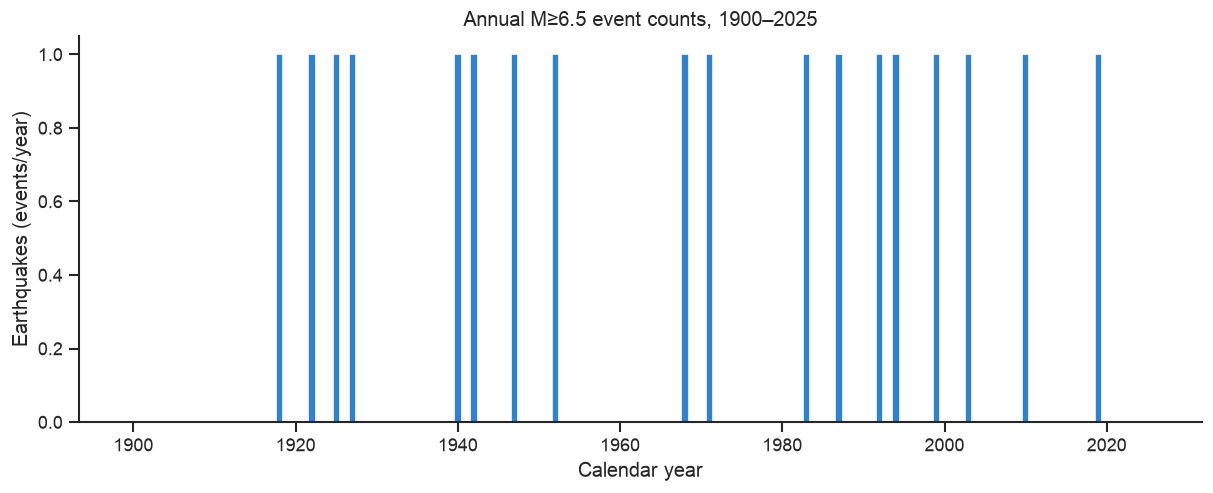

In [3]:
# Audit the frozen catalog and summarize annual counts.
print(f"Rows: {len(events)}; unique IDs: {events['id'].nunique()}; all IDs unique: {events['id'].is_unique}")
print(f"Time range: {events['time'].min()} through {events['time'].max()}")
print(f"All magnitudes >= 6.5: {events['mag'].ge(6.5).all()}")
print(f"All latitudes in [32, 37]: {events['latitude'].between(32, 37).all()}")
print(f"All longitudes in [-122, -114]: {events['longitude'].between(-122, -114).all()}")
print("Missing values by column:")
print(events.isna().sum().to_string())

total_events = int(annual_counts.sum())
zero_years = int(np.count_nonzero(annual_counts == 0))
max_annual_count = int(annual_counts.max())
print(f"Total events: {total_events}; zero-event years: {zero_years}; maximum annual count: {max_annual_count}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(YEARS, annual_counts, width=0.9, color="#3182ce")
ax.set(xlabel="Calendar year", ylabel="Earthquakes (events/year)", title="Annual M≥6.5 event counts, 1900–2025")
sns.despine(ax=ax)
plt.show()

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

The verified snapshot contains 18 events with 18 unique identifiers. Every recorded time is between 1900-01-01 and 2026-01-01, all magnitudes are at least 6.5, and all coordinates satisfy the stated latitude and longitude bounds. There is one missing depth; the other columns have no missing values. Depth is not part of this annual-count likelihood, so that missing value does not change the counts or the extract checks used here. The data contain 18 events in total, 108 zero-event years, and no year with more than one event.

I included all 126 calendar years, including years with no cataloged events. A zero is an observed count over one year of exposure, not a missing observation, so removing those years would incorrectly reduce the exposure in the Poisson likelihood. One limitation is that the catalog is a retrospective USGS extract and historical completeness and magnitude estimates can change over time; thus early and recent years may not be equally observable. The constant-rate model also treats the full window as exchangeable, an assumption that needs checking.

</div>

### 2.2 Prior information and sensitivity (15 points)

Compare these Gamma shape-rate priors for $\lambda$:

- **Maximum-entropy mean-only:** $\operatorname{Gamma}(1,8)$; positive
  support, mean $0.125$ events/year, and no other quantitative constraint
  relative to $q(\lambda)=1$ with respect to $d\lambda$ in the stated
  events/year coordinate.
- **Same-mean concentrated:** $\operatorname{Gamma}(4,32)$; hypothetical
  stronger prior information with the same mean.
- **Lower-rate sensitivity:** $\operatorname{Gamma}(2,40)$; hypothetical
  alternative with mean $0.05$ events/year.

Report each prior mean, standard deviation, and central 90% interval in
events/year. Plot all three densities on a common, readable rate range.
Explain why the first prior is exponential and how the first two priors can
have the same mean but express different information.


                           Mean (events/year)  SD (events/year)  90% lower  90% upper
Prior                                                                                
Maximum-entropy mean-only             0.12500           0.12500    0.00641    0.37447
Same-mean concentrated                0.12500           0.06250    0.04270    0.24230
Lower-rate sensitivity                0.05000           0.03536    0.00888    0.11860


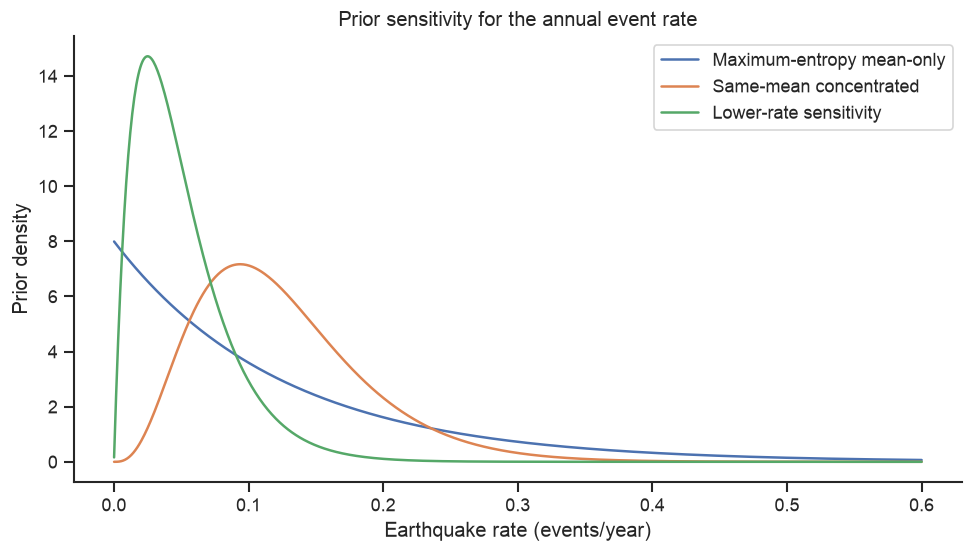

In [4]:
prior_specs = {
    "Maximum-entropy mean-only": (1.0, 8.0),
    "Same-mean concentrated": (4.0, 32.0),
    "Lower-rate sensitivity": (2.0, 40.0),
}

prior_rows = []
for name, (alpha, beta) in prior_specs.items():
    distribution = stats.gamma(a=alpha, scale=1.0 / beta)
    lower, upper = distribution.ppf([0.05, 0.95])
    prior_rows.append({
        "Prior": name,
        "Mean (events/year)": alpha / beta,
        "SD (events/year)": np.sqrt(alpha) / beta,
        "90% lower": lower,
        "90% upper": upper,
    })
prior_summary = pd.DataFrame(prior_rows).set_index("Prior")
print(prior_summary.to_string(float_format=lambda value: f"{value:.5f}"))

rate_grid = np.linspace(0.0001, 0.6, 800)
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (alpha, beta) in prior_specs.items():
    ax.plot(rate_grid, stats.gamma.pdf(rate_grid, a=alpha, scale=1.0 / beta), label=name)
ax.set(xlabel="Earthquake rate (events/year)", ylabel="Prior density", title="Prior sensitivity for the annual event rate")
ax.legend()
sns.despine(ax=ax)
plt.show()

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

The maximum-entropy mean-only prior has mean $0.1250$, standard deviation $0.1250$, and central 90% interval $[0.00641,\,0.37447]$ events/year. The same-mean concentrated prior has mean $0.1250$, standard deviation $0.06250$, and interval $[0.04270,\,0.24230]$. The lower-rate prior has mean $0.05000$, standard deviation $0.03536$, and interval $[0.00888,\,0.11860]$.

The first prior is exponential because a Gamma distribution with shape $\alpha=1$ has density proportional to $e^{-\beta\lambda}$ on positive support. The first two priors share a mean but not a variance: the higher shape and rate of Gamma$(4,32)$ encode a more concentrated belief around that mean. Gamma$(2,40)$ represents an alternative lower expected rate. These are sensitivity assumptions, not data-driven conclusions.

</div>

### 2.3 Posterior inference, credible intervals, and Bayes actions (20 points)

Implement the supplied Gamma–Poisson update using total count and total exposure.
For each prior, report the posterior shape and rate, mean, median, mode, and
central 95% credible interval for $\lambda$. Express rate summaries in both
events/year and events/decade. Plot the three posterior densities.

State which point summary is the Bayes action under squared-error loss and
which is the Bayes action under absolute-error loss. Report the continuous
posterior mode only as a density summary; do not use exact 0–1 loss to justify
it for a continuous parameter.


                             Shape  Rate (years)  Mean (events/year)  Mean (events/decade)  Median (events/year)  Mode (events/year)  95% lower (events/year)  95% upper (events/year)  95% lower (events/decade)  95% upper (events/decade)
Prior                                                                                                                                                                                                                                       
Maximum-entropy mean-only 19.00000     134.00000             0.14179               1.41791               0.13931             0.13433                  0.08537                  0.21230                    0.85367                    2.12297
Same-mean concentrated    22.00000     158.00000             0.13924               1.39241               0.13714             0.13291                  0.08726                  0.20317                    0.87261                    2.03169
Lower-rate sensitivity    20.00000     166.00000    

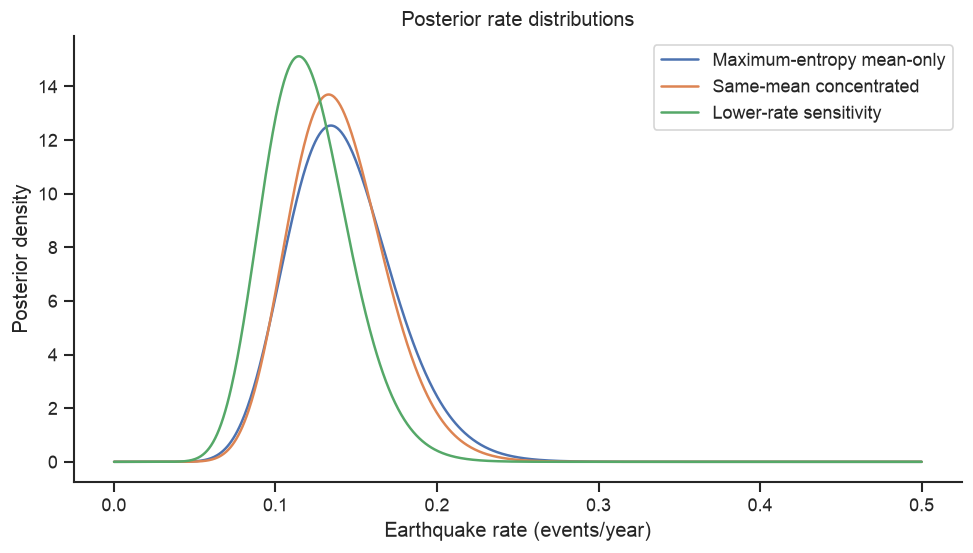

In [5]:
def gamma_poisson_update(alpha, beta, counts, exposure_years):
    '''Return posterior shape and rate for a Gamma–Poisson rate model.'''
    counts = np.asarray(counts)
    return alpha + counts.sum(), beta + exposure_years


posterior_specs = {
    name: gamma_poisson_update(alpha, beta, annual_counts, EXPOSURE_YEARS)
    for name, (alpha, beta) in prior_specs.items()
}

posterior_rows = []
for name, (alpha_post, beta_post) in posterior_specs.items():
    distribution = stats.gamma(a=alpha_post, scale=1.0 / beta_post)
    lower, upper = distribution.ppf([0.025, 0.975])
    posterior_rows.append({
        "Prior": name,
        "Shape": alpha_post,
        "Rate (years)": beta_post,
        "Mean (events/year)": alpha_post / beta_post,
        "Mean (events/decade)": 10.0 * alpha_post / beta_post,
        "Median (events/year)": distribution.median(),
        "Mode (events/year)": max((alpha_post - 1.0) / beta_post, 0.0),
        "95% lower (events/year)": lower,
        "95% upper (events/year)": upper,
        "95% lower (events/decade)": 10.0 * lower,
        "95% upper (events/decade)": 10.0 * upper,
    })
posterior_summary = pd.DataFrame(posterior_rows).set_index("Prior")
print(posterior_summary.to_string(float_format=lambda value: f"{value:.5f}"))

rate_grid = np.linspace(0.0001, 0.5, 800)
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (alpha_post, beta_post) in posterior_specs.items():
    ax.plot(rate_grid, stats.gamma.pdf(rate_grid, a=alpha_post, scale=1.0 / beta_post), label=name)
ax.set(xlabel="Earthquake rate (events/year)", ylabel="Posterior density", title="Posterior rate distributions")
ax.legend()
sns.despine(ax=ax)
plt.show()

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

The observed count is $n=18$ and the exposure is $E=126$ years. The posteriors are:

| Prior | Posterior | Mean (events/year; events/decade) | Median (events/year) | Mode (events/year) | Central 95% interval (events/year) |
|:--|:--|--:|--:|--:|:--|
| Maximum-entropy mean-only | Gamma$(19,134)$ | 0.14179; 1.41791 | 0.13931 | 0.13433 | [0.08537, 0.21230] |
| Same-mean concentrated | Gamma$(22,158)$ | 0.13924; 1.39241 | 0.13714 | 0.13291 | [0.08726, 0.20317] |
| Lower-rate sensitivity | Gamma$(20,166)$ | 0.12048; 1.20482 | 0.11848 | 0.11446 | [0.07359, 0.17874] |

In events/decade, the central 95% intervals are $[0.8537,\,2.1230]$, $[0.8726,\,2.0317]$, and $[0.7359,\,1.7874]$ for the three priors, respectively. Under squared-error loss, the posterior mean is the Bayes action; under absolute-error loss, it is the posterior median. The mode is useful as a summary of where the continuous density is highest, but an exact-value 0–1 loss is not an appropriate justification for a mode when the parameter is continuous.

</div>

### 2.4 Posterior-predictive model check (15 points)

Use the maximum-entropy prior's posterior for this check. Generate 50,000
replicated 126-year catalogs by repeating these two steps for each catalog:

1. draw $\lambda^{\mathrm{rep}}$ from the posterior;
2. draw 126 conditionally independent annual counts from
   $\operatorname{Poisson}(\lambda^{\mathrm{rep}})$.

Each replication is a synthetic 126-year catalog generated under the
posterior-predictive model. The sampled rate $\lambda^{\mathrm{rep}}$ remains
fixed across all 126 years within that catalog and is redrawn for the next
catalog. Variation in $\lambda^{\mathrm{rep}}$ across catalogs propagates
posterior uncertainty about the unknown rate; the Poisson draws represent
year-to-year count variability at a fixed rate.

Define the discrepancy

$$
T(\mathbf y)=\frac{s_y^2}{\bar y},
$$

where $s_y^2$ is the sample variance across years. The discrepancy compares
the across-year variability of the counts with their average annual level.
A Poisson random variable has variance equal to its mean, so $T=1$ is the
natural reference. Values above 1 indicate **overdispersion**, and values
below 1 indicate **underdispersion**. For a finite, sparse catalog, compare
the observed value with its posterior-predictive distribution rather than
judging it against 1 alone.

In this snapshot every observed annual count is either 0 or 1. Before
simulating, show that if $N>1$ and $1\leq n\leq N$ events occur across $N$
such annual counts, then

$$
T(\mathbf y)=\frac{N-n}{N-1}.
$$

Explain one kind of temporal behavior that this observed statistic cannot
detect.

The statistic is undefined for a replicated catalog whose total count is
zero. Exclude any such catalog and report how many were excluded. Report the
observed value and, conditional on a positive replicated total, the central
95% posterior-predictive interval for $T$ and the Bayesian tail area

$$
P\left(
T(\mathbf Y^{\mathrm{rep}})\geq T(\mathbf y)
\mid
\mathbf y,\,
\sum_tY_t^{\mathrm{rep}}>0
\right).
$$

Plot the replicated discrepancy distribution with the observed value marked.
Interpret what the check can and cannot establish about the homogeneous
Poisson model.


Observed T: 0.864000; binary-count formula: 0.864000
Replications with zero total events excluded: 0
Conditional central 95% predictive interval: [0.840000, 1.291200]
Bayesian upper-tail area: 0.928180


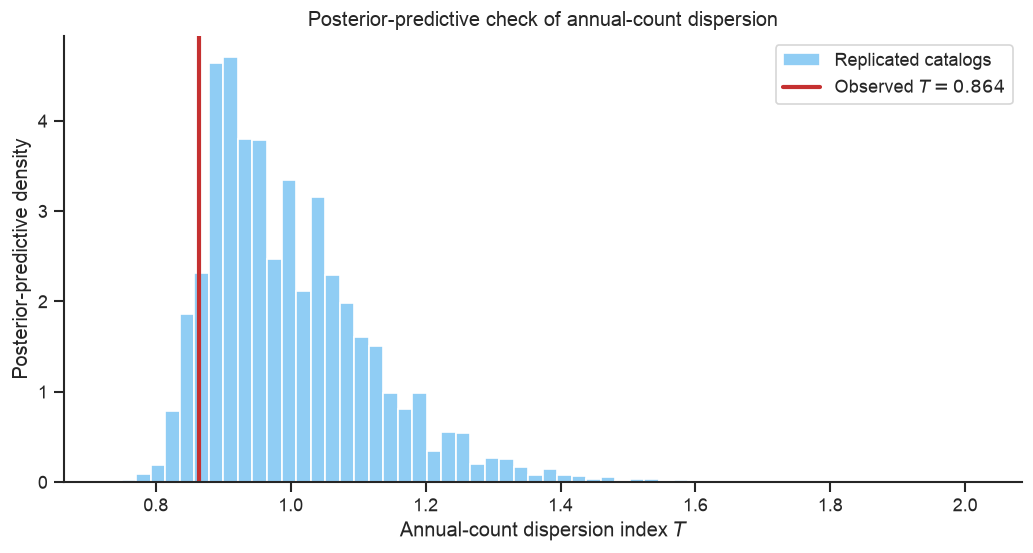

In [6]:
def simulate_replicated_catalogs(
    alpha_post,
    beta_post,
    n_years,
    n_replications=50_000,
    seed=SEED,
):
    '''Draw replicated annual-count catalogs from the posterior predictive.'''
    rng = np.random.default_rng(seed)
    rate_draws = rng.gamma(shape=alpha_post, scale=1.0 / beta_post, size=n_replications)
    return rng.poisson(rate_draws[:, None], size=(n_replications, n_years))


def dispersion_index(count_matrix):
    '''Return sample-variance/mean along the final axis.'''
    count_matrix = np.asarray(count_matrix)
    means = np.mean(count_matrix, axis=-1)
    variances = np.var(count_matrix, axis=-1, ddof=1)
    return np.divide(variances, means, out=np.full_like(means, np.nan, dtype=float), where=means > 0)


alpha_maxent, beta_maxent = posterior_specs["Maximum-entropy mean-only"]
replicated_counts = simulate_replicated_catalogs(
    alpha_maxent, beta_maxent, EXPOSURE_YEARS, n_replications=50_000, seed=SEED
)
all_discrepancies = dispersion_index(replicated_counts)
finite_discrepancies = all_discrepancies[np.isfinite(all_discrepancies)]
excluded_discrepancies = int(np.count_nonzero(~np.isfinite(all_discrepancies)))
observed_discrepancy = float(np.var(annual_counts, ddof=1) / np.mean(annual_counts))
predictive_interval = np.quantile(finite_discrepancies, [0.025, 0.975])
bayesian_tail_area = float(np.mean(finite_discrepancies >= observed_discrepancy))

print(f"Observed T: {observed_discrepancy:.6f}; binary-count formula: {(EXPOSURE_YEARS - total_events) / (EXPOSURE_YEARS - 1):.6f}")
print(f"Replications with zero total events excluded: {excluded_discrepancies}")
print(f"Conditional central 95% predictive interval: [{predictive_interval[0]:.6f}, {predictive_interval[1]:.6f}]")
print(f"Bayesian upper-tail area: {bayesian_tail_area:.6f}")

# Visualization code is supplied; it uses the quantities computed above.
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.hist(
    finite_discrepancies,
    bins=60,
    density=True,
    color="#90cdf4",
    edgecolor="white",
    label="Replicated catalogs",
)
ax.axvline(
    observed_discrepancy,
    color="#c53030",
    linewidth=2.5,
    label=fr"Observed $T={observed_discrepancy:.3f}$",
)
ax.set(
    xlabel=r"Annual-count dispersion index $T$",
    ylabel="Posterior-predictive density",
    title="Posterior-predictive check of annual-count dispersion",
)
ax.legend()
sns.despine(ax=ax)
plt.show()

<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

Because all 126 observed annual counts are either zero or one, let $n$ be the number of ones among $N=126$ years. Then $\bar y=n/N$ and $s_y^2=\frac{N}{N-1}\bar y(1-\bar y)$, so
$$
T=\frac{s_y^2}{\bar y}=\frac{N-n}{N-1}=\frac{126-18}{125}=0.864.
$$
This statistic does not use the ordering of the counts. For example, a cluster of event years and the same event years spread far apart can have the same $T$; therefore it cannot detect temporal clustering or trends by itself.

No simulated catalogs had zero total events, so none were excluded. The conditional central 95% posterior-predictive interval is $[0.8400,\,1.2912]$, and the upper-tail area is $0.9282$. The observed value is within the predictive interval and is not unusually large under this check. This is limited evidence that the annual dispersion is compatible with this fitted model; it does not establish a constant rate, rule out trends or dependence, or validate the data's changing historical completeness.

</div>

### 2.5 Ten- and twenty-year probabilities, sensitivity, and communication (15 points)

For each prior, calculate the exact posterior-predictive probabilities
$P(Y_*\ge1\mid\mathbf y)$ for $T=10$ and $T=20$ years. Compare each exact
value with the plug-in approximation

$$
1-\exp[-\mathbb{E}(\lambda\mid\mathbf y)T].
$$

A hypothetical preparedness rule triggers an action when the exact 20-year
probability is at least $0.90$. State the decision under each prior.

Then write 150–200 words for a technically literate decision maker. Your
explanation must distinguish expected count from probability of at least one
event, report the prior-sensitivity ranges for both the 10- and 20-year
horizons, state the action-rule result, and
identify at least two concrete limitations—one catalog-specific and one
model-specific. Do not present this calculation as an official forecast.


In [7]:
horizons = (10, 20)
probability_rows = []
for name, (alpha_post, beta_post) in posterior_specs.items():
    posterior_mean = alpha_post / beta_post
    row = {"Prior": name}
    for horizon in horizons:
        exact_probability = 1.0 - (beta_post / (beta_post + horizon)) ** alpha_post
        plug_in_probability = 1.0 - np.exp(-posterior_mean * horizon)
        row[f"Exact {horizon}-year probability"] = exact_probability
        row[f"Plug-in {horizon}-year probability"] = plug_in_probability
    row["Trigger at 20 years"] = row["Exact 20-year probability"] >= 0.90
    probability_rows.append(row)
probability_summary = pd.DataFrame(probability_rows).set_index("Prior")
print(probability_summary.to_string(float_format=lambda value: f"{value:.5f}"))
print("\nPrior-sensitivity ranges:")
for horizon in horizons:
    values = probability_summary[f"Exact {horizon}-year probability"]
    print(f"{horizon} years: {values.min():.5f} to {values.max():.5f}")

                           Exact 10-year probability  Plug-in 10-year probability  Exact 20-year probability  Plug-in 20-year probability  Trigger at 20 years
Prior                                                                                                                                                         
Maximum-entropy mean-only                    0.74526                      0.75778                    0.92886                      0.94133                 True
Same-mean concentrated                       0.74079                      0.75152                    0.92735                      0.93826                 True
Lower-rate sensitivity                       0.68961                      0.70025                    0.89722                      0.91015                False

Prior-sensitivity ranges:
10 years: 0.68961 to 0.74526
20 years: 0.89722 to 0.92886


<div style="background-color: #fff9c4; border-left: 4px solid #f2c94c; padding: 0.75em 1em; border-radius: 6px;">

For this snapshot, the posterior expected count is the posterior mean rate multiplied by exposure: across the three priors it is about 1.205–1.418 events in 10 years and 2.410–2.836 in 20 years. That expected count is not the probability of at least one event: multiple events are possible, so the probability is a different summary of the predictive count distribution. The exact probability of one or more events is 0.6896–0.7453 over 10 years and 0.8972–0.9289 over 20 years. The plug-in estimates are slightly higher in each case because they substitute the posterior mean rate rather than average the probability over rate uncertainty. Under the hypothetical 0.90 rule, the maximum-entropy and same-mean concentrated priors trigger action; the lower-rate sensitivity prior does not.

These numbers depend on a small frozen catalog, which may have changing historical completeness and magnitude estimates; it also covers a rectangular California–Baja region and only events of magnitude 6.5 or greater. The model-specific limitation is that one constant rate and independent Poisson annual counts cannot represent changing seismicity or temporal dependence. This is a model-based exercise for the specified catalog and assumptions, not an official earthquake forecast or a complete measure of local hazard.

</div>

## Problem 2 data source and credit

The automatically loaded CSV is a frozen extract from the U.S. Geological Survey's
[ANSS Comprehensive Earthquake Catalog (ComCat)](https://earthquake.usgs.gov/data/comcat/)
([catalog DOI 10.5066/F7MS3QZH](https://doi.org/10.5066/F7MS3QZH)), queried
through the official [FDSN event web service](https://earthquake.usgs.gov/fdsnws/event/1/).
The [exact query](https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv&starttime=1900-01-01&endtime=2026-01-01&minlatitude=32&maxlatitude=37&minlongitude=-122&maxlongitude=-114&minmagnitude=6.5&orderby=time-asc)
requested CSV output, start time `1900-01-01`, end time `2026-01-01`,
latitude 32–37 degrees N, longitude −122 to −114 degrees, minimum magnitude
6.5, and ascending event time. The snapshot was retrieved August 17, 2026;
only `time`, `latitude`, `longitude`, `depth`, `mag`, `place`, and `id` were
retained and sorted by time.

**Frozen-file SHA-256:**
`a4e7fb0d2a99fc81cf0f309e13a853b6025413e84d61ab82f18cc8c43ec37072`.

The Bayesian Poisson treatment of uncertain earthquake rates and future
occurrence probabilities is informed by
[Love (2012)](https://pubs.usgs.gov/publication/70045154) and
[Rotondi (2013)](https://academic.oup.com/gji/article/195/1/381/599171).
The frozen California–Baja snapshot, prior-information exercise,
posterior-predictive check, and 10/20-year comparison were assembled for
this assignment.

The setup cell first accepts a matching local course copy and otherwise
downloads the frozen
[Homework 3 course-data file](../data/homework/southern-california-baja-earthquakes-1900-2025.csv).
It verifies the bytes against the checksum before parsing them. The USGS
query above documents provenance only; this notebook never executes that
mutable live query.

USGS catalogs can be revised. This fixed file is used for reproducibility.
The reported quantity is a **model-based probability of at least one catalog
event under the constant-rate Poisson model**, not earthquake risk or an
authoritative California forecast. For California's scientific long-term
forecast resources, see the
[California Geological Survey's UCERF page](https://www.conservation.ca.gov/cgs/Pages/Earthquakes/UCERF3.aspx).

## Submission checklist

- Both numbered problems total 100 points.
- Every code cell runs from top to bottom and the setup reports a verified
  data source; no manual data upload is required.
- All figures have labels and units.
- The 150–200 word communication is included.
- No response cell still contains placeholder text.
